<br>
<font>
<div dir=ltr align=center>
<img src="https://cdn.freebiesupply.com/logos/large/2x/sharif-logo-png-transparent.png" width=150 height=150> <br>
<font color=0F5298 size=7>
    Machine learning <br>
<font color=2565AE size=5>
    Computer Engineering Department <br>
    Fall 2025<br>
<font color=3C99D size=5>
    Practical Assignment 5 - NLP - Word Embeddings & Fine-Tuning <br>
</div>
<div dir=ltr align=center>
<font color=0CBCDF size=4>
     Emad Rostamian, Seyed Moein Ayyoubzadeh
<br>
<font color=0CBCDF size=4>
</div>

____

<font color=9999FF size=4>
Full Name : arshia nazari
<br>
<font color=9999FF size=4>
Student Number : 402106701

<font color=0080FF size=3>
This notebook covers two related topics in modern NLP. In the first part, we study word embedding methods, including traditional and neural approaches, to understand how semantic information is represented in vector space. In the second part, we explore fine-tuning strategies for pretrained language models, with a focus on parameter-efficient methods such as LoRA, and analyze their behavior during training.
</font>

# Section 1: Exploring Word Embeddings

## 🎯 Objective

In this section, you will **build, explore, and compare different types of word representations (embeddings)** to understand how machines capture the meaning of words from text.


---

## 📚 Dataset

We will work with the complete **_Harry Potter_ series (Books 1–7)**, loaded from a public Hugging Face dataset.

⚠️ **Note:** This text is used **only for educational purposes**.


---

## 🛠️ What You Will Do

You will:
1. **Implement from scratch**
   - TF-IDF
   - Word2Vec-style embeddings (CBOW and Skip-Gram)
   - Nearest-neighbor search (word similarity)
2. **GloVe: Global Vectors for Word Representation**
   - Exploring word vectors
   - Word Analogies

## Part 1: Implement from scratch

## 1. Traditional Word Representations: TF-IDF

Before learning dense vector embeddings, we start with a **traditional and interpretable** way of representing words: **TF-IDF**.

TF-IDF does *not* try to learn meaning from prediction tasks. Instead, it represents words based on how **frequently** they appear and how **informative** they are across documents.

---

## Term Frequency (TF)

Term Frequency measures how often a word appears in a document.

For a word $ w $ in document $ d $:

$$
\text{TF}(w, d) = \frac{\text{count of } w \text{ in } d}{\text{total number of words in } d}
$$

Intuition:
- Words that appear often in a document are likely important *for that document*

---

## Inverse Document Frequency (IDF)

Inverse Document Frequency downweights words that appear in *many* documents.

$$
\text{IDF}(w) = \log\left(\frac{1 + N}{1 + \text{DF}(w)}\right) + 1
$$

Where:
- $ N $ = total number of documents  
- $ \text{DF}(w) $ = number of documents containing word \( w \)

Why the **+1** terms:
- `+1` in the denominator prevents division by zero  
- `+1` in the numerator keeps the ratio ≥ 1  
- `+1` outside the log prevents zero IDF values  

Intuition:
- Common words get low weight  
- Rare words get high weight  
- All words keep a positive contribution  


---

## TF-IDF Score

The final TF-IDF representation combines both ideas:

$$
\text{TF-IDF}(w, d) = \text{TF}(w, d) \times \text{IDF}(w)
$$

Each document is represented as a **high-dimensional sparse vector**, where:
- Each dimension corresponds to a word in the vocabulary
- Values reflect word importance


---

## Your Task

In this section, you will:

1. Load **Harry Potter and the Sorcerer’s Stone**
2. Split the book into **chapters** (each chapter = one document)
3. Build **TF-IDF vectors from scratch**
4. Use TF-IDF to:
   - Find the most important words in a chapter
   - Compute similarity between chapters
   - Compare words based on their TF-IDF representations

Do **not** use `sklearn`’s `TfidfVectorizer`.

The goal is to understand *how TF-IDF works internally*.


In [38]:
# Standard library
import re
import math
import random
from collections import Counter, defaultdict

# Third-party libraries
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Hugging Face
from datasets import load_dataset

# Scikit-learn
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import string
from collections import Counter
import math
import numpy as np
# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [36]:
# Load dataset
hp_ds = load_dataset("elricwan/HarryPotter")

# Each book is one document
books = hp_ds["train"]

# Extract book texts
documents = [book["content"] for book in books]
documents = documents[:-1]
print(f"Number of books: {len(documents)}")


Number of books: 7


In [56]:
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in ENGLISH_STOP_WORDS]
    return tokens

docs = [preprocess(doc) for doc in documents]

for i, doc in enumerate(docs):
    print(f"Book {i+1}: {len(doc)} tokens")


Book 1: 38759 tokens
Book 2: 44839 tokens
Book 3: 55465 tokens
Book 4: 95330 tokens
Book 5: 126688 tokens
Book 6: 82121 tokens
Book 7: 94453 tokens


In [57]:
corpus = []
for doc in docs:
    corpus.extend(doc)

vocab = Counter(corpus)

threshold = 5
vocab = {w: c for w, c in vocab.items() if c >= threshold}

word2idx = {w: i for i, w in enumerate(vocab.keys())}
idx2word = {i: w for w, i in word2idx.items()}

corpus_idxs = [word2idx[w] for w in corpus if w in word2idx]

print(f"Corpus size: {len(corpus_idxs)}")
print(f"Vocabulary size: {len(vocab)}")


Corpus size: 513283
Vocabulary size: 9116


In [58]:
def tf(doc):
    out = defaultdict(float)
    n = len(doc)
    for w in doc:
        out[w] += 1.0 / n
    return dict(out)

tf_docs = [tf(doc) for doc in docs]

def idf(docs):
    N = len(docs)
    df = defaultdict(int)
    for doc in docs:
        for w in set(doc):
            df[w] += 1
    out = {}
    for w, c in df.items():
        out[w] = math.log((1 + N) / (1 + c)) + 1
    return out

idf_dict = idf(docs)

def compute_tfidf(tf_dict, idf_dict):
    return {w: tf_dict[w] * idf_dict[w] for w in tf_dict}

tfidf_docs = [compute_tfidf(tf_doc, idf_dict) for tf_doc in tf_docs]


In [59]:
def top_k_words(tfidf_doc, k=5):
    return sorted(tfidf_doc.items(), key=lambda x: x[1], reverse=True)[:k]

for i, tfidf_doc in enumerate(tfidf_docs):
    top = top_k_words(tfidf_doc, k=5)
    print(f"Book {i+1}: {[w for w, _ in top]}")


Book 1: ['harry', 'said', 'ron', 'hagrid', 'hermione']
Book 2: ['harry', 'said', 'ron', 'hermione', 'lockhart']
Book 3: ['harry', 'said', 'ron', 'hermione', 'lupin']
Book 4: ['harry', 'said', 'ron', 'hermione', 'dumbledore']
Book 5: ['said', 'harry', 'hermione', 'ron', 'umbridge']
Book 6: ['harry', 'said', 'dumbledore', 'ron', 'slughorn']
Book 7: ['harry', 'said', 'hermione', 'ron', 'wand']


In [60]:
def tfidf_vector_for_word(word, tfidf_docs):
    return [doc.get(word, 0.0) for doc in tfidf_docs]

word = "harry"
vec = tfidf_vector_for_word(word, tfidf_docs)
print(f"TF-IDF vector for '{word}': {vec}")


TF-IDF vector for 'harry': [0.03330839288939297, 0.03570552420883631, 0.03409357252321166, 0.03183677750970484, 0.029584491033090868, 0.031989381522387214, 0.03083014832773937]


### Questions


1.   In the TF-IDF vector you just computed for the word "harry", what does each element of the vector represent?


> Your Answer



2.   In your own words, what are the main limitations of TF-IDF as a word representation? Consider whether TF-IDF captures meaning, similarity between words, and relationships such as analogies.

> Your Answer



## 2. Word2Vec: CBOW and Skip-Gram

TF-IDF represents words using **counts and statistics**, but it does not capture *semantic meaning*.
To go beyond this, we rely on a key idea in linguistics and NLP:

> **You shall know a word by the company it keeps.**

This idea is known as the **distributional hypothesis**.

Instead of counting words, we now **learn** word vectors by training a model to predict words from their surrounding context.

---

## Word2Vec: Learning Word Embeddings

Word2Vec learns *static* (context-independent) word embeddings by solving a **prediction task**.
However, directly predicting a word from the entire vocabulary using a softmax is computationally expensive.

To make training efficient, Word2Vec uses **negative sampling**.

---

## Word2Vec: Two Training Objectives

Word2Vec uses one of two training objectives to generate these positive and negative examples:

### 🔹 CBOW (Continuous Bag of Words)
- **Input:** surrounding context words
- **Target:** the center word

### 🔹 Skip-Gram
- **Input:** center word
- **Target:** surrounding context words
---
### 🔹 What is Negative Sampling?

Negative sampling reformulates word prediction as a **binary classification problem**:

- **Positive examples**: word pairs that actually occur together in the text
- **Negative examples**: randomly sampled word pairs that do *not* occur together

Instead of scoring against the whole vocabulary, the model only compares:
- one true (positive) word
- a small number of randomly sampled (negative) words

This dramatically reduces computation while still producing high-quality embeddings.

### 🔹 Why Negative Sampling Works

By training the model to:
- **increase similarity** for real context–word pairs
- **decrease similarity** for randomly sampled pairs

 the learned vectors capture semantic and syntactic relationships between words.

---

In this section, you will:

1. Generate **(context, target)** training pairs from text  
2. Implement **CBOW and Skip-Gram with negative sampling from scratch**  
3. Train word embeddings using a simple neural objective  
4. Explore the learned embeddings by:
   - Finding nearest neighbors
   - Performing word analogies
   - Comparing CBOW vs Skip-Gram behavior

Do **not** use `gensim` or prebuilt Word2Vec implementations.

The goal is to understand **how embeddings are learned**, not just how to use them.


### Build sliding windows

Use `torch.unfold` to create windows of size `2w+1`, then split into:
- `centers`: middle token  
- `contexts`: left+right tokens (center removed)


In [61]:
def make_windows(corpus_idxs, window_size):
    corpus_tensor = torch.tensor(corpus_idxs, dtype=torch.long)
    windows = corpus_tensor.unfold(0, 2 * window_size + 1, 1)
    centers = windows[:, window_size]
    contexts = torch.cat([windows[:, :window_size], windows[:, window_size + 1:]], dim=1)
    return contexts, centers


### Negative-sampling distribution

Build the unigram distribution $P(w) \propto \text{count}(w)^{0.75}$ for sampling negative words.


In [62]:
def build_unigram_dist(word_counts, vocab_size, word2idx, power=0.75):
    counts = np.zeros(vocab_size)
    for word, count in word_counts.items():
        if word in word2idx:
            counts[word2idx[word]] = count
    dist = counts ** power
    dist = dist / dist.sum()
    return torch.from_numpy(dist).float()

unigram_dist = build_unigram_dist(vocab, len(vocab), word2idx)


### Negative sampling utilities

Sample $k$ negative words per example and compute the **negative sampling loss**:  

$$\log\sigma(s^{+}) + \sum \log\sigma(-s^{-})$$


In [63]:
@torch.no_grad()
def sample_negatives(dist_on_device, batch_size, k):
    return torch.multinomial(
        dist_on_device,
        batch_size * k,
        replacement=True
    ).view(batch_size, k)


def negative_sampling_loss(pos_score, neg_score):
    pos_loss = -F.logsigmoid(pos_score).mean()
    neg_loss = -F.logsigmoid(-neg_score).sum(dim=1).mean()
    return pos_loss + neg_loss


### CBOW
Create a CBOW dataset (`contexts → center`) and a CBOW model that returns positive/negative scores for the **negative sampling loss**.


In [64]:
class CBOWDataset(Dataset):
    def __init__(self, contexts, centers):
        self.contexts = contexts
        self.centers = centers

    def __len__(self):
        return len(self.centers)

    def __getitem__(self, idx):
        return self.contexts[idx], self.centers[idx]


In [65]:
class CBOW(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.embeddings_in = nn.Embedding(vocab_size, embedding_dim)
        self.embeddings_out = nn.Embedding(vocab_size, embedding_dim)

    def forward(self, context_idxs, target_idxs, neg_idxs):
        ctx_emb = self.embeddings_in(context_idxs).mean(dim=1)
        tgt_emb = self.embeddings_out(target_idxs)
        neg_emb = self.embeddings_out(neg_idxs)

        pos_score = (ctx_emb * tgt_emb).sum(dim=1)
        neg_score = torch.bmm(
            neg_emb,
            ctx_emb.unsqueeze(2)
        ).squeeze(2)

        return pos_score, neg_score


#### Train CBOW

Training loop for CBOW: sample negatives, compute scores, apply negative sampling loss, and update embeddings.


In [67]:
def train_cbow(model, loader, dist, optimizer, neg_k, epochs):
    model.train()
    dist = dist.to(device)

    for e in range(epochs):
        total_loss = 0
        for contexts, centers in tqdm(loader, desc=f"CBOW Epoch {e+1}/{epochs}"):
            contexts = contexts.to(device)
            centers = centers.to(device)

            neg_idxs = sample_negatives(dist, centers.size(0), neg_k)

            optimizer.zero_grad()
            pos_score, neg_score = model(contexts, centers, neg_idxs)
            loss = negative_sampling_loss(pos_score, neg_score)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {e+1} | Loss: {total_loss/len(loader):.4f}")


In [68]:
window_size = 2
contexts, centers = make_windows(corpus_idxs, window_size=window_size)

CBOW_BATCH = 2048
NEG_K = 10
EMBED_DIM = 50
EPOCHS = 5
LR = 0.003

cbow_dataset = CBOWDataset(contexts, centers)
cbow_loader = DataLoader(cbow_dataset, batch_size=CBOW_BATCH, shuffle=True)

cbow = CBOW(len(vocab), EMBED_DIM).to(device)
cbow_opt = optim.Adam(cbow.parameters(), lr=LR)

train_cbow(cbow, cbow_loader, unigram_dist, cbow_opt, NEG_K, EPOCHS)



CBOW Epoch 1/5: 100%|██████████| 251/251 [00:05<00:00, 46.59it/s]


Epoch 1 | Loss: 14.3389


CBOW Epoch 2/5: 100%|██████████| 251/251 [00:04<00:00, 51.60it/s]


Epoch 2 | Loss: 7.3989


CBOW Epoch 3/5: 100%|██████████| 251/251 [00:04<00:00, 52.12it/s]


Epoch 3 | Loss: 4.8430


CBOW Epoch 4/5: 100%|██████████| 251/251 [00:05<00:00, 46.35it/s]


Epoch 4 | Loss: 4.1455


CBOW Epoch 5/5: 100%|██████████| 251/251 [00:04<00:00, 53.13it/s]

Epoch 5 | Loss: 3.7737


### Skip-gram

Create (`center`, `context`) training pairs and a Skip-gram model that scores positive and negative contexts for the negative sampling loss.


In [69]:
class SkipGramPairDataset(Dataset):
    def __init__(self, contexts, centers):
        self.pairs = []
        for i in range(len(centers)):
            c = centers[i].item()
            for ctx in contexts[i]:
                self.pairs.append((c, ctx.item()))

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        return self.pairs[idx]


In [70]:
class SkipGram(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.embeddings_in = nn.Embedding(vocab_size, embedding_dim)
        self.embeddings_out = nn.Embedding(vocab_size, embedding_dim)

    def forward(self, centers, pos_ctx, neg_ctx):
        c_emb = self.embeddings_in(centers)
        p_emb = self.embeddings_out(pos_ctx)
        n_emb = self.embeddings_out(neg_ctx)

        pos_score = (c_emb * p_emb).sum(dim=1)
        neg_score = torch.bmm(
            n_emb,
            c_emb.unsqueeze(2)
        ).squeeze(2)

        return pos_score, neg_score


#### Train Skip-gram

Training loop for Skip-gram with negative sampling: sample negatives, compute scores, apply negative sampling loss, and update embeddings.


In [71]:
def train_skipgram(model, loader, dist, optimizer, neg_k, epochs):
    model.train()
    dist = dist.to(device)

    for e in range(epochs):
        total_loss = 0
        for centers, pos_ctx in tqdm(loader, desc=f"SG Epoch {e+1}/{epochs}"):
            centers = torch.tensor(centers).to(device)
            pos_ctx = torch.tensor(pos_ctx).to(device)

            neg_ctx = sample_negatives(dist, centers.size(0), neg_k)

            optimizer.zero_grad()
            pos_score, neg_score = model(centers, pos_ctx, neg_ctx)
            loss = negative_sampling_loss(pos_score, neg_score)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {e+1} | Loss: {total_loss/len(loader):.4f}")


In [72]:
window_size = 2
contexts, centers = make_windows(corpus_idxs, window_size=window_size)

SG_BATCH = 4096
NEG_K = 10
EMBED_DIM = 50
EPOCHS = 5
LR = 0.003

sg_dataset = SkipGramPairDataset(contexts, centers)
sg_loader = DataLoader(sg_dataset, batch_size=SG_BATCH, shuffle=True)

skipgram = SkipGram(len(vocab), EMBED_DIM).to(device)
sg_opt = optim.Adam(skipgram.parameters(), lr=LR)

train_skipgram(skipgram, sg_loader, unigram_dist, sg_opt, NEG_K, EPOCHS)



SG Epoch 1/5:   0%|          | 0/502 [00:00<?, ?it/s]/var/folders/f4/624yxyvs0tjc0bl3l_z_9x1m0000gn/T/ipykernel_31870/1480237601.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  centers = torch.tensor(centers).to(device)
/var/folders/f4/624yxyvs0tjc0bl3l_z_9x1m0000gn/T/ipykernel_31870/1480237601.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  pos_ctx = torch.tensor(pos_ctx).to(device)
SG Epoch 1/5: 100%|██████████| 502/502 [00:12<00:00, 40.48it/s]


Epoch 1 | Loss: 20.2917


SG Epoch 2/5: 100%|██████████| 502/502 [00:11<00:00, 42.42it/s]


Epoch 2 | Loss: 6.8309


SG Epoch 3/5: 100%|██████████| 502/502 [00:11<00:00, 42.14it/s]


Epoch 3 | Loss: 4.3439


SG Epoch 4/5: 100%|██████████| 502/502 [00:12<00:00, 40.55it/s]


Epoch 4 | Loss: 3.7659


SG Epoch 5/5: 100%|██████████| 502/502 [00:11<00:00, 42.09it/s]

Epoch 5 | Loss: 3.5115


### Inspect learned embeddings

Implement helper functions to (1) fetch a word vector from the input/output embedding tables and (2) find nearest neighbors using the combined embedding $(E_{in}+E_{out})/2$.


In [73]:
def get_embedding(model, word, embedding_space="in"):
    idx = word2idx[word]
    if embedding_space == "in":
        return model.embeddings_in.weight[idx].detach().cpu()
    else:
        return model.embeddings_out.weight[idx].detach().cpu()

@torch.no_grad()
def nearest_words_combined(model, word, k=10):
    idx = word2idx[word]
    emb = (model.embeddings_in.weight + model.embeddings_out.weight) / 2
    emb = emb.cpu()

    query = emb[idx]
    sims = F.cosine_similarity(query.unsqueeze(0), emb)

    top = sims.topk(k + 1)
    results = []
    for i in top.indices:
        w = idx2word[i.item()]
        if w != word:
            results.append(w)
        if len(results) == k:
            break
    return results




### Query nearest neighbors

Compare CBOW vs Skip-gram by printing the top-5 nearest words to a query term **"hogwarts"** using the combined embedding space.


In [74]:
word = "hogwarts"
print(f"CBOW | Nearest words for '{word}': {nearest_words_combined(cbow, word, 5)}")
print(f"Skip-gram | Nearest words for '{word}': {nearest_words_combined(skipgram, word, 5)}")


CBOW | Nearest words for 'hogwarts': ['shed', 'spellwork', 'bath', 'sacking', 'curled']
Skip-gram | Nearest words for 'hogwarts': ['time', 'pairs', 'punishment', 'night', 'potters']


## Questions

You observed the nearest neighbors of **"hogwarts"** using both CBOW and Skip-Gram (You are encouraged to test additional words to build better intuition).


Answer the following questions:  


1. **Which model produced more semantically meaningful neighbors?**  
   Justify your answer based on the words returned.

   > Your Answer

2. **Why do you think CBOW shows higher cosine similarity scores than Skip-Gram?**  
   Consider how each model aggregates or distributes context information.

   > Your Answer

3. **Why might Skip-Gram return more diverse or less “obvious” neighbors?**  
   What does this tell you about how Skip-Gram learns word representations?
   > Your Answer



## Part 2: GloVe – Global Vectors for Word Representation

GloVe is a pre-trained word embedding model developed by Stanford University. It learns word representations by leveraging global word–word co-occurrence statistics from large text corpora, resulting in embeddings that capture semantic relationships between words. Words with similar meanings tend to have vectors that are close to each other in the embedding space.

At the core of GloVe is the construction of a **global co-occurrence matrix** $X$, where each entry $X_{ij}$ represents how often word $j$ appears in the context of word $i$ across the entire corpus. Rather than using these raw counts directly, GloVe learns word embeddings by minimizing the following weighted least-squares objective:

$$
J = \sum_{i,j=1}^{V} f(X_{ij})
\left( \mathbf{w}_i^\top \mathbf{\tilde{w}}_j + b_i + \tilde{b}_j - \log X_{ij} \right)^2
$$

where:
- $\mathbf{w}_i$ is the vector representation of the target word $i$
- $\mathbf{\tilde{w}}_j$ is the vector representation of the context word $j$
- $b_i$ and $\tilde{b}_j$ are bias terms
- $f(X_{ij})$ is a weighting function that downweights very frequent and very rare co-occurrences

The weighting function is defined as:

$$
f(x) =
\begin{cases}
\left( \frac{x}{x_{\text{max}}} \right)^\alpha & \text{if } x < x_{\text{max}} \\
1 & \text{if } x \ge x_{\text{max}}
\end{cases}
$$

with typical values $x_{\text{max}} = 100$ and $\alpha = 0.75$.

This objective encourages the **dot product of word vectors** to approximate the logarithm of their co-occurrence counts, allowing linear relationships in the embedding space to encode meaningful semantic regularities.

In this implementation, we load a pre-trained GloVe model using **Gensim’s downloader API**. Specifically, the model `glove-wiki-gigaword-300` is used, which was trained on a combination of Wikipedia and Gigaword text containing approximately 6 billion tokens. Each word in the vocabulary is represented by a **300-dimensional** dense vector.

The vocabulary consists of all tokens for which embeddings are available in the pre-trained model. These embeddings can be directly used for downstream NLP tasks such as similarity computation, clustering, or as input features for machine learning models.


In [78]:
# run this code to install gensim on your environment
!pip install gensim

In [ ]:
import torch
import numpy as np
from urllib.request import urlretrieve
import zipfile
import os

def download_glove():
    url = "https://nlp.stanford.edu/data/glove.6B.zip"
    zip_path = "glove.6B.zip"
    
    if not os.path.exists("glove.6B.300d.txt"):
        print("Downloading GloVe...")
        urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extract("glove.6B.300d.txt")
        os.remove(zip_path)
        print("Download complete!")
    else:
        print("GloVe already downloaded")

download_glove()

def load_glove_manual(path="glove.6B.300d.txt"):
    words = []
    vectors = []
    
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            words.append(parts[0])
            vectors.append([float(x) for x in parts[1:]])
    
    return words, np.array(vectors, dtype=np.float32)

words, vectors = load_glove_manual()

word2idx_glove = {w: i for i, w in enumerate(words)}
idx2word_glove = {i: w for i, w in enumerate(words)}

E_glove = torch.tensor(vectors, dtype=torch.float32)
E_glove = E_glove / E_glove.norm(dim=1, keepdim=True)

print(f"Loaded GloVe: {len(words)} words, {vectors.shape[1]} dimensions")


Download complete!
Loaded GloVe: 400000 words, 300 dimensions


### Building GloVe Embedding Utilities

This section constructs helper data structures and functions for working with GloVe embeddings in PyTorch.

First, we build mappings between words and indices (`word2idx` and `idx2word`) and create an embedding matrix `E_glove` of shape `(V, D)`, where `V` is the vocabulary size and `D` is the embedding dimension.

To enable efficient cosine similarity computation, the embedding matrix is L2-normalized once in advance.

Two utility functions are provided:
- **`get_glove_embedding(word)`**: Returns the embedding vector for a given word.
- **`nearest_words_glove(word, k)`**: Finds the top-`k` most similar words to a query word using cosine similarity.

These utilities support fast embedding lookup and semantic similarity queries.


In [ ]:
def get_glove_embedding(word):
    if word not in word2idx_glove:
        raise KeyError(f"'{word}' not in GloVe vocabulary")
    return E_glove[word2idx_glove[word]]

@torch.no_grad()
def nearest_words_glove(word, k=10):
    query = get_glove_embedding(word)
    sims = E_glove @ query
    vals, idxs = torch.topk(sims, k + 1)
    
    results = []
    for idx in idxs.tolist():
        w = idx2word_glove[idx]
        if w != word:
            results.append(w)
        if len(results) == k:
            break
    return results

for w in ["harry", "wizard", "magic", "hogwarts", "dumbledore"]:
    try:
        print(f"{w} -> {nearest_words_glove(w, k=5)}")
    except KeyError as e:
        print(f"OOV: {e}")


harry -> ['potter', 'reid', 'truman', 'rowling', 'belafonte']
wizard -> ['oz', 'sorcerer', 'magician', 'magical', 'wicked']
magic -> ['magical', 'wizards', 'wand', 'orlando', 'magician']
hogwarts -> ['dumbledore', 'wizardry', 'hermione', 'voldemort', 'hagrid']
dumbledore -> ['voldemort', 'albus', 'hogwarts', 'snape', 'hagrid']


Test the GloVe similarity function on Harry Potter related words and compare the results with Word2Vec models

In [86]:
for w in ["harry", "wizard", "magic", "hogwarts", "dumbledore"]:
    try:
        print(w, "->", nearest_words_glove(w, k=5))
    except KeyError as e:
        print("OOV:", e)

harry -> ['potter', 'reid', 'truman', 'rowling', 'belafonte']
wizard -> ['oz', 'sorcerer', 'magician', 'magical', 'wicked']
magic -> ['magical', 'wizards', 'wand', 'orlando', 'magician']
hogwarts -> ['dumbledore', 'wizardry', 'hermione', 'voldemort', 'hagrid']
dumbledore -> ['voldemort', 'albus', 'hogwarts', 'snape', 'hagrid']


### Word Analogies

One standard method for assessing word embeddings, first popularized in *Efficient Estimation of Word Representations in Vector Space*, is to examine pairs of words that exhibit the same semantic or morphological relationship. For example, the pairs *fast → faster* and *slow → slower* follow an identical pattern.

Each pair can be interpreted as an analogy question:  
“What word corresponds to *slow* in the same way that *faster* corresponds to *fast*?”

These relationships can be resolved through vector arithmetic in the embedding space. We compute

$$
x = w_{\text{faster}} - w_{\text{fast}} + w_{\text{slow}}
$$

and then search the vocabulary for the word vector that is most similar to \(x\). In this notebook, similarity is measured using cosine similarity, resulting in the following objective:

$$
w^{*} = \arg\max_{w} \cos\left(w,\; w_{\text{faster}} - w_{\text{fast}} + w_{\text{slow}}\right)
$$


In [104]:
@torch.no_grad()
def vector_arithmetic(a, b, c, top_k=5):
    va = get_glove_embedding(a)
    vb = get_glove_embedding(b)
    vc = get_glove_embedding(c)
    
    v = vb - va + vc
    v = v / v.norm()
    
    sims = E_glove @ v
    vals, idxs = torch.topk(sims, top_k + 3)
    
    results = []
    exclude = {a, b, c}
    for idx in idxs.tolist():
        w = idx2word_glove[idx]
        if w not in exclude:
            results.append(w)
        if len(results) == top_k:
            break
    return results



In [105]:
# TODO: Verify that vector arithmetic produces the expected analogy result using GloVe vectors
test_set = [
    ["rome", "italy", "madrid", "spain"],
    ["berlin", "germany", "vienna", "austria"],
    ["beijing", "china", "seoul", "korea"],
    ["king", "queen", "prince", "princess"],
    ["actor", "actress", "waiter", "waitress"],
    ["teach", "teacher", "drive", "driver"],
    ["happy", "happier", "cold", "colder"],
    ["strong", "strongest", "weak", "weakest"],
    ["write", "writing", "swim", "swimming"],
    ["buy", "bought", "go", "went"],
    ["leaf", "leaves", "wolf", "wolves"],
    ["child", "children", "person", "people"],
    ["spain", "spanish", "greece", "greek"],
]
for a, b, c, expected in test_set:

    predicted = vector_arithmetic(a,b, c, top_k=1)[0]
    
    va = get_glove_embedding(a)
    vb = get_glove_embedding(b)
    vc = get_glove_embedding(c)
    
    analogy_vec = vb - va + vc
    analogy_vec = analogy_vec / analogy_vec.norm()
    
    pred_vec = get_glove_embedding(predicted)
    similarity = (analogy_vec @ pred_vec).item()
    
    print(f"{b} - {a} + {c}  →  expected: {expected}")
    print(f"Result:  {predicted:<12} {similarity:.4f}")
    print("-" * 40)

italy - rome + madrid  →  expected: spain
Result:  spain        0.6885
----------------------------------------
germany - berlin + vienna  →  expected: austria
Result:  austria      0.7446
----------------------------------------
china - beijing + seoul  →  expected: korea
Result:  korea        0.8010
----------------------------------------
queen - king + prince  →  expected: princess
Result:  princess     0.6948
----------------------------------------
actress - actor + waiter  →  expected: waitress
Result:  waitress     0.7234
----------------------------------------
teacher - teach + drive  →  expected: driver
Result:  drives       0.5640
----------------------------------------
happier - happy + cold  →  expected: colder
Result:  colder       0.6168
----------------------------------------
strongest - strong + weak  →  expected: weakest
Result:  weakest      0.6113
----------------------------------------
writing - write + swim  →  expected: swimming
Result:  swimming     0.6603
-


# Section 2: Geometry of Fine-Tuning — Measuring ΔM and ΔD During Training

## Context
In recent papers on **parameter-efficient fine-tuning (PEFT)**, authors analyze *how weights move* during training. Two common geometry-inspired quantities are:

- **ΔM (magnitude change)**: how much *column norms* change.
- **ΔD (direction change)**: how much *column directions* change, often via cosine similarity.

In this homework, you will replicate a lightweight version of a "paper-style" analysis on a small BERT model, comparing:
1. **Full fine-tuning**
2. **LoRA(https://arxiv.org/abs/2106.09685)**
3. **DoRA(https://arxiv.org/abs/2402.09353)**

You will:
- fine-tune on **AG News (4-class)**,
- capture intermediate weight snapshots for **attention query/value** projection matrices,
- compute ΔM and ΔD over time,
- visualize the relationship between ΔM and ΔD,
- and answer analysis questions about what you observe.

## Learning Objectives
By the end, you should be able to:
- Implement a reproducible NLP training pipeline with `datasets` and `transformers`.
- Implement *column-wise* geometry metrics for weight updates.
- Instrument training to capture intermediate model states.
- Compare training-time geometry across optimization regimes (Full FT vs PEFT).
- Communicate empirical findings with appropriate plots and statistical summaries.

## What you must submit
1. This notebook with all **@ToDo** items completed.
2. All plots requested in the notebook.
3. Short written answers to the **analysis questions** at the end.

## Rules
- Do not change the definitions of ΔM and ΔD beyond what is specified (unless explicitly asked).
- You may tune hyperparameters *only* where the notebook indicates it is allowed.
- Your analysis must be based on your results (not copied from others).


---
## Step 0 — Environment and Setup

### What you should do and why
You will install the required libraries and set deterministic seeds. Reproducibility is essential for comparing geometry across methods: if runs are not controlled, you may attribute differences to LoRA/DoRA when they are actually caused by randomness.


In [ ]:

import os, re, time, math, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    TrainerCallback,
)
import evaluate
import peft
from peft import LoraConfig, get_peft_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

import transformers, datasets
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("peft:", peft.__version__)


device: cpu
torch: 2.8.0
transformers: 5.0.0
datasets: 3.3.2
peft: 0.18.1



---
## Step 1 — Load the Dataset (AG News)

### What you should do and why
You will load **AG News** and create smaller train/eval splits to keep the homework runnable on modest hardware. The goal is not to maximize accuracy, but to **compare geometry across training methods under similar conditions**.


In [ ]:

ds = load_dataset("ag_news")

TRAIN_SIZE = 8000 if device == "cuda" else 1500
EVAL_SIZE  = 1500 if device == "cuda" else 400

TRAIN_SIZE = min(TRAIN_SIZE, len(ds["train"]))
EVAL_SIZE  = min(EVAL_SIZE, len(ds["test"]))

train_ds = ds["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
eval_ds  = ds["test"].shuffle(seed=SEED).select(range(EVAL_SIZE))
print("train size:", len(train_ds), "eval size:", len(eval_ds))

for i in range(2):
    print(f"\nExample {i}:")
    print("label:", train_ds[i]["label"])
    print("text :", train_ds[i]["text"][:200], "…")


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

train size: 1500 eval size: 400

Example 0:
label: 0
text : Bangladesh paralysed by strikes Opposition activists have brought many towns and cities in Bangladesh to a halt, the day after 18 people died in explosions at a political rally. …

Example 1:
label: 1
text : Desiring Stability Redskins coach Joe Gibbs expects few major personnel changes in the offseason and wants to instill a culture of stability in Washington. …



---
## Step 2 — Tokenization and Dataset Preprocessing

### What you should do and why
Transformers expect tokenized inputs. You will implement a batching tokenizer function that:
- tokenizes text with truncation,
- sets a maximum length,
- and creates a `labels` field required by `Trainer`.

This step is foundational: incorrect labels or tokenization will invalidate the training and the geometry analysis.


In [ ]:

model_name = "google/bert_uncased_L-4_H-256_A-4"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_with_labels(batch):
    output = tokenizer(batch["text"], truncation=True, max_length=192)
    output["labels"] = batch["label"]
    return output
    raise NotImplementedError("Implement tokenize_with_labels")


train_tok = train_ds.map(tokenize_with_labels, batched=True, remove_columns=train_ds.column_names)
eval_tok  = eval_ds.map(tokenize_with_labels,  batched=True, remove_columns=eval_ds.column_names)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(train_tok[0].keys())


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])



---
## Step 3 — Define Evaluation Metrics

### What you should do and why
Accuracy is a simple sanity metric for AG News. You will implement the `compute_metrics` callback that converts logits into predicted class IDs.

This is used to:
- compare Full FT vs LoRA vs DoRA in terms of *task performance*,
- and ensure training is actually working before interpreting geometry plots.


In [ ]:
acc = evaluate.load("accuracy")

def compute_metrics(eval_pred):
   
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)
    return acc.compute(predictions=predictions, references=labels)
    raise NotImplementedError("Implement compute_metrics")



---
## Step 4 — Training Helpers (Parameters, Arguments)

### What you should do and why
You will implement lightweight helper functions:
- count parameters (total vs trainable),
- create TrainingArguments compatible with older/newer Transformers.

These utilities help quantify the *efficiency* of PEFT methods and keep the training loop clean.


In [ ]:

def count_params(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total_params, trainable_params
    raise NotImplementedError("Implement count_params")

def short_model_report(model, title="model"):
    total, trainable = count_params(model)
    print(f"[{title}] total params: {total:,}")
    print(f"[{title}] trainable params: {trainable:,} ({trainable/total:.4%})")

def make_training_args(outdir, lr, epochs, batch=32, eval_every="epoch"):
    base = dict(
        output_dir=outdir,
        report_to=[],
        logging_steps=50,
        save_strategy="no",
        fp16=(device=="cuda"),
        learning_rate=lr,
        weight_decay=0.01,
        warmup_ratio=0.06,
        lr_scheduler_type="cosine",
        num_train_epochs=epochs,
        per_device_train_batch_size=batch if device=="cuda" else max(8, batch//2),
        per_device_eval_batch_size=64,
        gradient_accumulation_steps=1,
    )
    try:
        return TrainingArguments(evaluation_strategy=eval_every, **base)
    except TypeError:
        return TrainingArguments(eval_strategy=eval_every, **base)



---
## Step 5 — Implement Paper-Style ΔM and ΔD (Column-Wise)

### What you should do and why
You will implement the *core geometry metrics*:

- Let W ∈ R^{d_out × d_in}.
- Consider each **column** as a vector in R^{d_out}.

Definitions (column-wise):
- Column norms: ||W[:, j]||_2
- **ΔM**: mean absolute change in column norms from initialization
- **ΔD**: 1 − mean cosine similarity between current and initial columns

These are used in the final scatter plot of ΔD vs ΔM and should match the definitions in the provided design.


In [ ]:

def col_norms(W: torch.Tensor) -> torch.Tensor:
    W = W.float()
    return torch.linalg.vector_norm(W, dim=0)
    raise NotImplementedError("Implement col_norms")

def mean_cosine_cols(A: torch.Tensor, B: torch.Tensor) -> torch.Tensor:
    A = A.float()
    B = B.float()
    
    norms_A = torch.linalg.vector_norm(A, dim=0)
    norms_B = torch.linalg.vector_norm(B, dim=0)
    
    A_norm = A / (norms_A + 1e-12)
    B_norm = B / (norms_B + 1e-12)
    
    cos_sims = (A_norm * B_norm).sum(dim=0)
    
    return cos_sims.mean()
    raise NotImplementedError("Implement mean_cosine_cols")

def delta_M_D(W0: torch.Tensor, Wt: torch.Tensor):
    """
    Compute (ΔM, ΔD) between initial weight W0 and current weight Wt.

    Definitions:
      m0 = column norms of W0
      mt = column norms of Wt
      ΔM = mean |mt - m0|
      cos_mean = mean cosine similarity between columns of Wt and W0
      ΔD = 1 - cos_mean

    @ToDo:
    - Implement using col_norms and mean_cosine_cols.
    - Return Python floats (not tensors).
    """
    W0 = W0.float()
    Wt = Wt.float()
    
    norms_0 = col_norms(W0)
    norms_t = col_norms(Wt)
    
    delta_M = (norms_t - norms_0).abs().mean().item()
    
    cos_mean = mean_cosine_cols(W0, Wt).item()
    delta_D = 1.0 - cos_mean
    
    return delta_M, delta_D
    raise NotImplementedError("Implement delta_M_D")



---
## Step 6 — Capture Intermediate Weight Snapshots (Query/Value Only)

### What you should do and why
We need intermediate snapshots across training (not only at the end). You will:

1. Identify **target parameter names** matching BERT attention query/value weights:
   - `bert.encoder.layer.{i}.attention.self.query.weight`
   - `bert.encoder.layer.{i}.attention.self.value.weight`

2. Implement a TrainerCallback that captures these tensors at selected training steps.

This instrumentation enables time-resolved geometry analysis similar to paper plots showing how weights evolve *during* fine-tuning.


In [ ]:
TARGET_REGEX = re.compile(r"bert\.encoder\.layer\.\d+\.attention\.self\.(query|value)\.weight$")

def select_target_param_names(model):
    """
    Return sorted parameter names that match TARGET_REGEX.

    @ToDo:
    - Iterate model.named_parameters()
    - Select names that match TARGET_REGEX
    - Return sorted list of names
    """
    # @ToDo
    target_names = []
    for name, param in model.named_parameters():
        if re.search(r'\b(query|value)\b', name) and param.ndim == 2:
            target_names.append(name)
    return target_names

    raise NotImplementedError("Implement select_target_param_names")

class WeightSnapshotCallback(TrainerCallback):
    def __init__(self, target_names, capture_steps):
        super().__init__()
        self.target_names = target_names
        self.capture_steps = set(capture_steps)
        self.snapshots = {}
        self.model = None

    def on_train_begin(self, args, state, control, model=None, **kwargs):
        self.model = model
        
    def on_step_end(self, args, state, control, model=None, **kwargs):
        if model is None:
            model = self.model
        if state.global_step in self.capture_steps:
            self.snapshots[state.global_step] = {
                n: model.state_dict()[n].detach().cpu().clone()
                for n in self.target_names
            }

def choose_capture_steps(total_steps):
    """
    Choose capture steps similar to paper-style intermediate points.

    @ToDo:
    - Return a sorted unique list containing:
      [0, 20%, 50%, 80%, 100%] of total_steps (rounded to int)
    - Ensure steps are at least 1 where appropriate (except 0).
    """
    # @ToDo
    steps = [
        0,
        int(round(0.2 * total_steps)),
        int(round(0.5 * total_steps)),
        int(round(0.8 * total_steps)),
        int(round(1.0 * total_steps)),
    ]
    steps = sorted(set([s if s == 0 else max(1, s) for s in steps]))
    return steps
    raise NotImplementedError("Implement choose_capture_steps")



---
## Step 7 — Training With Snapshots

### What you should do and why
You will write a training wrapper that:
- creates a callback with selected capture steps,
- stores an explicit step-0 snapshot (initial weights),
- trains with `Trainer.train()`,
- evaluates at the end,
- and returns snapshots + metrics.

This wrapper ensures the only difference between methods is **which parameters are trained**, not how we collect geometry.


In [ ]:
def train_with_snapshots(model, outdir, lr, epochs, batch=32):
    """
    Train a model while capturing intermediate snapshots of query/value weights.

    Returns:
      trainer, metrics_dict, snapshots_dict

    @ToDo:
    - Move model to device.
    - Select target param names with select_target_param_names.
    - Estimate total_steps and choose capture steps.
      Hint: steps_per_epoch = ceil(len(train_tok) / per_device_batch_size)
    - Instantiate WeightSnapshotCallback.
    - Create TrainingArguments via make_training_args.
    - Create Trainer with callbacks=[cb].
    - Store an explicit snapshot at step=0 in cb.snapshots.
    - Train, measure train time, evaluate.
    - Return (trainer, metrics, cb.snapshots).
    """
    # @ToDo
    import time, math

    model = model.to(device)
    targets = select_target_param_names(model)

    steps_per_epoch = math.ceil(len(train_tok) / batch)
    total_steps = steps_per_epoch * epochs
    capture_steps = choose_capture_steps(total_steps)

    cb = WeightSnapshotCallback(targets, capture_steps)
    args = make_training_args(outdir, lr, epochs, batch)

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_tok,
        eval_dataset=eval_tok,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[cb],
    )

    cb.snapshots[0] = {
        n: model.state_dict()[n].detach().cpu().clone()
        for n in targets
    }

    start = time.time()
    trainer.train()
    train_time = time.time() - start

    eval_metrics = trainer.evaluate()
    return trainer, {
        "eval_accuracy": eval_metrics["eval_accuracy"],
        "train_seconds": train_time,
    }, cb.snapshots



---
## Step 8 — Build ΔM/ΔD Point Cloud

### What you should do and why
After training, you will convert snapshots into a table where each row corresponds to:
- a method (full/lora/dora),
- a training step,
- a specific weight matrix name,
- and its geometry relative to initialization.

This tabular representation supports scatter plots, density plots, and correlation analysis.


In [ ]:
def build_points(snapshots, method):
    """
    Create a DataFrame with columns:
      method, step, name, dM, dD

    For each captured step and each target weight matrix:
      compute (ΔM, ΔD) between W0 and Wt.

    @ToDo:
    - Sort steps.
    - Let W0 = snapshots[0].
    - For each step and each name present in W0:
        - compute dM, dD = delta_M_D(W0[name], snapshots[step][name])
        - append row
    - Return pd.DataFrame(rows)
    """
    # @ToDo
    rows = []
    steps = sorted(snapshots.keys())
    W0 = snapshots[0]
    
    for step in steps:
        if step == 0:
            continue
        
        Wt = snapshots[step]
        for name in W0:
            if name in Wt:
                dM, dD = delta_M_D(W0[name], Wt[name])
                rows.append({
                    "method": method,
                    "step": step,
                    "name": name,
                    "dM": dM,
                    "dD": dD,
                })
    
    return pd.DataFrame(rows)
    raise NotImplementedError("Implement build_points")



---
## Step 9 — Correlation Utilities (Pearson and Spearman)

### What you should do and why
A typical paper-style question is: *are magnitude and direction changes related?*

You will implement:
- Pearson correlation (linear association),
- Spearman correlation (rank-based, monotonic association).

These will be computed per method on the point cloud.


In [ ]:
def pearson(x, y):
    """
    @ToDo:
    - Convert to float arrays.
    - Drop non-finite values.
    - Return np.corrcoef(x, y)[0,1] if length >= 3 else nan.
    """
    # @ToDo
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    
    if len(x) < 3:
        return np.nan
    
    return np.corrcoef(x, y)[0, 1]
    raise NotImplementedError("Implement pearson")

def spearman(x, y):
    """
    @ToDo:
    - Convert to float arrays.
    - Drop non-finite values.
    - Rank x and y (average ranks for ties).
    - Return Pearson correlation of ranks if length >= 3 else nan.
    """
    # @ToDo
    
    
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    
    if len(x) < 3:
        return np.nan
    
    rx = rankdata(x, method="average")
    ry = rankdata(y, method="average")
    
    return np.corrcoef(rx, ry)[0, 1]
    raise NotImplementedError("Implement spearman")


In [ ]:

---
## Step 10 — Define Methods: Full FT vs LoRA vs DoRA

### What you should do and why
You will instantiate and train three variants:

1. **Full fine-tuning**: all parameters trainable.
2. **LoRA**: train low-rank adapters on attention query/value modules.
3. **DoRA**: if supported, uses a decomposition that can alter geometry differently than LoRA.

You will record:
- number of trainable parameters,
- final eval accuracy,
- training time,
- and geometry point clouds.


In [ ]:

EPOCHS_FULL = 3
EPOCHS_ADAPTER = 6
LR_FULL = 2e-5
LR_ADAPTER = 3e-4
BATCH = 32

def make_lora_model(model_name, num_labels=4, use_dora=False):
    """
    Create a (LoRA or DoRA) model for sequence classification.

    @ToDo:
    - Load base model: AutoModelForSequenceClassification.from_pretrained(...)
    - Create LoraConfig with:
        r=8, lora_alpha=16, lora_dropout=0.05,
        bias="none", task_type="SEQ_CLS",
        target_modules=["query", "value"]
      If use_dora=True, include use_dora=True in config (if supported).
    - Wrap with get_peft_model and return it.
    """
    # @ToDo
    base_model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=num_labels
    )
    
    config = {
        "r": 8,
        "lora_alpha": 16,
        "lora_dropout": 0.05,
        "bias": "none",
        "task_type": TaskType.SEQ_CLS,
        "target_modules": ["query", "value"],
    }
    
    if use_dora:
        config["use_dora"] = True
    
    lora_cfg = LoraConfig(**config)
    return get_peft_model(base_model, lora_cfg)
    raise NotImplementedError("Implement make_lora_model")


In [ ]:

full_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=4)
short_model_report(full_model, "full-ft (before)")

trainer_full, metrics_full, snaps_full = train_with_snapshots(
    full_model,
    outdir="out_full_agnews_bert4",
    lr=LR_FULL,
    epochs=EPOCHS_FULL,
    batch=BATCH
)
print("full metrics:", metrics_full)
print("full captured steps:", sorted(snaps_full.keys()))


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were n

[full-ft (before)] total params: 11,171,588
[full-ft (before)] trainable params: 11,171,588 (100.0000%)


/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,Accuracy
1,1.394947,1.403816,0.245000
2,1.392467,1.401895,0.240000
3,1.394894,1.401538,0.250000


/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


full metrics: {'eval_accuracy': 0.25, 'train_seconds': 40.004279136657715}
full captured steps: [0, 28, 70, 113, 141]


In [ ]:
from peft import TaskType

lora_model = make_lora_model(model_name, num_labels=4, use_dora=False)
short_model_report(lora_model, "lora (before)")
try:
    lora_model.print_trainable_parameters()
except Exception as e:
    print("Could not print trainable parameters:", e)

trainer_lora, metrics_lora, snaps_lora = train_with_snapshots(
    lora_model,
    outdir="out_lora_agnews_bert4",
    lr=LR_ADAPTER,
    epochs=EPOCHS_ADAPTER,
    batch=BATCH
)
print("lora metrics:", metrics_lora)
print("lora captured steps:", sorted(snaps_lora.keys()))


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were n

[lora (before)] total params: 11,205,384
[lora (before)] trainable params: 33,796 (0.3016%)
trainable params: 33,796 || all params: 11,205,384 || trainable%: 0.3016


/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,Accuracy
1,1.407384,1.379493,0.335000
2,1.374631,1.359988,0.327500
3,1.336451,1.269689,0.455000
4,1.215862,1.187291,0.510000
5,1.173201,1.158898,0.497500
6,1.135149,1.153766,0.507500


/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning:

lora metrics: {'eval_accuracy': 0.5075, 'train_seconds': 45.406267166137695}
lora captured steps: [0, 56, 141, 226, 282]


In [ ]:

snaps_dora = None
metrics_dora = {"skipped": True}

try:
    dora_model = make_lora_model(model_name, num_labels=4, use_dora=True)
    short_model_report(dora_model, "dora (before)")
    try:
        dora_model.print_trainable_parameters()
    except Exception as e:
        print("Could not print trainable parameters:", e)

    trainer_dora, metrics_dora, snaps_dora = train_with_snapshots(
        dora_model,
        outdir="out_dora_agnews_bert4",
        lr=LR_ADAPTER,
        epochs=EPOCHS_ADAPTER,
        batch=BATCH
    )
    print("dora metrics:", metrics_dora)
    print("dora captured steps:", sorted(snaps_dora.keys()))

except TypeError as e:
    print("DoRA not supported by this PEFT version. Skipping DoRA.")
    print("Error:", e)


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were n

[dora (before)] total params: 11,207,432
[dora (before)] trainable params: 35,844 (0.3198%)
trainable params: 35,844 || all params: 11,207,432 || trainable%: 0.3198


/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,Accuracy
1,1.395827,1.389086,0.312500
2,1.365247,1.366541,0.347500
3,1.338251,1.305675,0.400000
4,1.251543,1.213138,0.442500
5,1.200463,1.191742,0.460000
6,1.177956,1.187741,0.457500


/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/lib/python3.12/site-packages/torch/utils/data/dataloader.py:684: UserWarning:

dora metrics: {'eval_accuracy': 0.4575, 'train_seconds': 41.27310585975647}
dora captured steps: [0, 56, 141, 226, 282]



---
## Step 11 — Assemble All Points and Compute Correlations

### What you should do and why
You will build a combined DataFrame for all methods and focus on **query weights** (often closest to paper plots).

Then you will compute correlation summaries:
- Pearson(ΔD, ΔM)
- Spearman(ΔD, ΔM)

These summaries help quantify trends you see in scatter plots.


In [ ]:
from scipy.stats import rankdata

df_full = build_points(snaps_full, "full")
df_lora = build_points(snaps_lora, "lora")

dfs = [df_full, df_lora]
if snaps_dora is not None:
    df_dora = build_points(snaps_dora, "dora")
    dfs.append(df_dora)

df = pd.concat(dfs, ignore_index=True)
print("points:", len(df))

df_q = df[df["name"].str.contains(r"\.query\.weight$", regex=True)].copy()
print("points (query only):", len(df_q))

summary = []
for m in sorted(df_q["method"].unique()):
    sub = df_q[df_q["method"] == m]
    summary.append({
        "method": m,
        "n_points": len(sub),
        "pearson(dD, dM)": pearson(sub["dD"], sub["dM"]),
        "spearman(dD, dM)": spearman(sub["dD"], sub["dM"]),
    })
summary_df = pd.DataFrame(summary)
summary_df


points: 224
points (query only): 16


,method,n_points,"pearson(dD, dM)","spearman(dD, dM)"
0,full,16,0.905285,0.967647



---
## Step 12 — Plots: Scatter and Hexbin (Paper-Style)

### What you should do and why
You will plot ΔD vs ΔM for each method.
- Scatter plots show raw point clouds.
- Hexbin plots provide a density-like view similar to many papers.

Include Pearson and Spearman in the plot titles to connect visual patterns with quantitative summaries.


In [147]:
def scatter_all(df_use, title_suffix="(query weights)"):
    methods = sorted(df_use["method"].unique())
    n = len(methods)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5))
    if n == 1:
        axes = [axes]
    
    for ax, m in zip(axes, methods):
        sub = df_use[df_use["method"] == m]
        x = sub["dD"].values
        y = sub["dM"].values
        
        mask = np.isfinite(x) & np.isfinite(y)
        x = x[mask]
        y = y[mask]
        
        r = pearson(x, y)
        rs = spearman(x, y)
        
        ax.scatter(x, y, alpha=0.4, s=20)
        ax.set_xlabel("ΔD")
        ax.set_ylabel("ΔM")
        ax.set_title(f"{m} {title_suffix}\nPearson={r:.3f}, Spearman={rs:.3f}")
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def hexbin_all(df_use, gridsize=35, title_suffix="(query weights)"):
    methods = sorted(df_use["method"].unique())
    n = len(methods)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5))
    if n == 1:
        axes = [axes]
    
    for ax, m in zip(axes, methods):
        sub = df_use[df_use["method"] == m]
        x = sub["dD"].values
        y = sub["dM"].values
        
        mask = np.isfinite(x) & np.isfinite(y)
        x = x[mask]
        y = y[mask]
        
        r = pearson(x, y)
        rs = spearman(x, y)
        
        hb = ax.hexbin(x, y, gridsize=gridsize, cmap="viridis", mincnt=1)
        ax.set_xlabel("ΔD")
        ax.set_ylabel("ΔM")
        ax.set_title(f"{m} {title_suffix}\nPearson={r:.3f}, Spearman={rs:.3f}")
        plt.colorbar(hb, ax=ax, label="count")
    
    plt.tight_layout()
    plt.show()



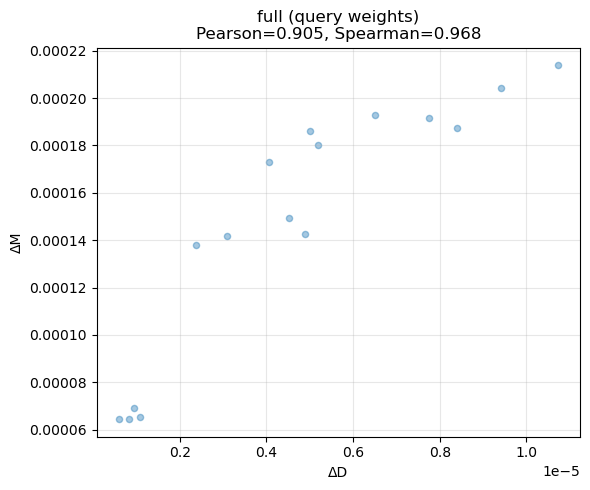

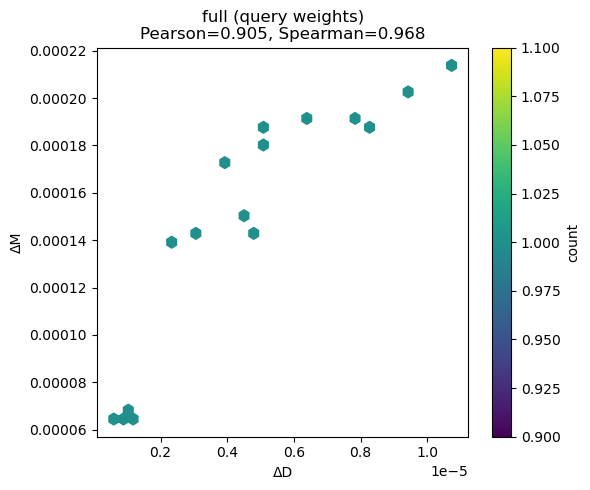

In [148]:

# Produce plots (once you implement plotting functions)
scatter_all(df_q)
hexbin_all(df_q)



---
## Step 13 — Training Metrics Summary Table

### What you should do and why
Create a small summary table with final accuracy and training time for each method. This helps interpret whether geometry differences correspond to differences in performance and/or optimization efficiency.


In [149]:

train_results = [
    {"method": "full", "eval_accuracy": metrics_full.get("eval_accuracy"), "train_seconds": metrics_full.get("train_seconds")},
    {"method": "lora", "eval_accuracy": metrics_lora.get("eval_accuracy"), "train_seconds": metrics_lora.get("train_seconds")},
]
if snaps_dora is None:
    train_results.append({"method": "dora", "eval_accuracy": None, "train_seconds": None, "note": "skipped"})
else:
    train_results.append({"method": "dora", "eval_accuracy": metrics_dora.get("eval_accuracy"), "train_seconds": metrics_dora.get("train_seconds")})

pd.DataFrame(train_results)


,method,eval_accuracy,train_seconds
0,full,0.2500,40.004279
1,lora,0.5075,45.406267
2,dora,0.4575,41.273106



---
# Analysis Questions (Answer in Markdown)

Answer concisely but precisely. Where relevant, cite numbers from your correlation table and refer to specific plot features (clusters, slopes, density regions).

1. **Sanity checks**
   1. What accuracy did you obtain for each method?
   2. Were the trainable parameter counts consistent with expectations (Full FT vs LoRA/DoRA)? Provide the counts.

2. **Geometry–performance relationship**
   1. Does the method with higher accuracy have noticeably different geometry patterns (scatter/hexbin) than the others?
   2. Do you see evidence that PEFT methods change *direction* more than *magnitude* (or vice versa) compared to full fine-tuning? Explain.

3. **Correlation interpretation**
   1. Compare Pearson vs Spearman for each method. Are they similar? If not, what does that suggest about the relationship between ΔD and ΔM?
   2. Which method has the strongest association between ΔD and ΔM? Provide correlation values.

4. **Step-wise dynamics**
   1. Look at points grouped by step (you may color points by step if you want). Do early steps differ from late steps?
   2. Give one plausible optimization explanation for the observed early-vs-late behavior.

5. **Query vs Value**
   1. Repeat the analysis for **value weights** only (`.value.weight`). Do conclusions change?
   2. Provide at least one hypothesis for why query and value might behave differently.

6. **Method critique**
   1. Identify at least two limitations of this experiment design (e.g., dataset size, step sampling, metric choices).
   2. Propose one extension that would strengthen the evidence (e.g., multiple seeds, additional layers, other target modules).

7. **Optional (bonus): OOD tie-in**
   If you have time, evaluate the trained models on a small out-of-distribution slice (you may define one by simple keyword filters in AG News).
   1. Do geometry patterns correlate with OOD robustness in your quick test?
   2. What additional experiments would be needed to make a credible claim?
